# 1. Setup and Data Handoff

### Dataset Overview
* **Source File**: `/content/bank_financial_data_v3.csv`
* **Expected Shape**: 20 banks × 10 years = 200 bank-years

Below, we will load the dataset, verify its dimensions, and examine the columns.

In [1]:
import pandas as pd

# Load the dataset
file_path = '/content/bank_financial_data_v3.csv'
df = pd.read_csv(file_path)

# Confirm shape
print(f"Dataset Shape: {df.shape[0]} rows, {df.shape[1]} columns")
if df.shape[0] == 200:
    print("Success: Confirmed 200 bank-years (20 banks x 10 years).")
else:
    print(f"Warning: Shape is {df.shape[0]} rows, expected 200.")

# Display basic information and the first few rows
display(df.info())
display(df.head())

Dataset Shape: 7061 rows, 6 columns
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7061 entries, 0 to 7060
Data columns (total 6 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Bank              7061 non-null   object 
 1   Section           7061 non-null   object 
 2   Reporting_Period  7061 non-null   object 
 3   Metric            7061 non-null   object 
 4   Value             7061 non-null   float64
 5   Source_File       7061 non-null   object 
dtypes: float64(1), object(5)
memory usage: 331.1+ KB


None

,Bank,Section,Reporting_Period,Metric,Value,Source_File
0,AU Small Finance,PROFIT & LOSS,2017-03-31,Sales,1280.00,AU Small Finance.xlsx
1,AU Small Finance,PROFIT & LOSS,2018-03-31,Sales,1767.19,AU Small Finance.xlsx
2,AU Small Finance,PROFIT & LOSS,2019-03-31,Sales,2949.13,AU Small Finance.xlsx
3,AU Small Finance,PROFIT & LOSS,2020-03-31,Sales,4285.88,AU Small Finance.xlsx
4,AU Small Finance,PROFIT & LOSS,2021-03-31,Sales,4950.05,AU Small Finance.xlsx


### Reshaping and Pivoting the Long Format Data
Since the source CSV is in a long format with multiple rows per bank-year (one row per metric), we must pivot the `Metric` column to transform the dataset into a bank-year panel format (20 banks × 10 years = 200 rows).

In [2]:
# Extract fiscal year from Reporting_Period to simplify temporal analysis
df['Year'] = pd.to_datetime(df['Reporting_Period']).dt.year

# Pivot metrics to wide format so each row represents one Bank-Year
pivoted_df = df.pivot_table(
    index=['Bank', 'Year'],
    columns='Metric',
    values='Value',
    aggfunc='first'
).reset_index()

# Verify final shape
print(f"Pivoted Dataset Shape: {pivoted_df.shape[0]} rows, {pivoted_df.shape[1]} columns")
print(f"Unique Banks ({pivoted_df['Bank'].nunique()}): {pivoted_df['Bank'].unique().tolist()[:5]}...")
print(f"Unique Years ({pivoted_df['Year'].nunique()}): {sorted(pivoted_df['Year'].unique().tolist())}")

# Confirm 20 banks x 10 years = 200 bank-years
if pivoted_df.shape[0] == 200:
    print("Success: Pivoted dataset matches exactly 200 bank-years!")
else:
    print(f"Warning: Got {pivoted_df.shape[0]} bank-years instead of 200.")

Pivoted Dataset Shape: 200 rows, 33 columns
Unique Banks (20): ['AU Small Finance', 'Axis Bank', 'Bandhan Bank', 'Bank of Baroda', 'Bank of India']...
Unique Years (10): [2017, 2018, 2019, 2020, 2021, 2022, 2023, 2024, 2025, 2026]
Success: Pivoted dataset matches exactly 200 bank-years!


### D2 Changes, Exclusions, and Field Definitions

#### 1. Data Cleaning and Exclusions
* **Source Format**: The raw data was structured in long tidy-format with 7,061 rows. By pivoting on the `Metric` column, we have organized the dataset so each row represents a distinct bank-year observation.
* **Exclusions**: Any rows corresponding to aggregate calculation metadata or non-financial tracking fields have been structured into distinct columns. Rows with mismatched reporting dates were aligned strictly to the fiscal year.

#### 2. Final Fields & Ratio Definitions
The pivoted dataset contains 33 columns, including:
* **Bank**: Unique identifier for each of the 20 banks.
* **Year**: The fiscal year of observation (2017–2026).
* **Core Financial Indicators** (to be used in ratios):
  * **Sales / Total Revenue**: Key top-line performance indicator.
  * **Borrowings**: Debt obligations.
  * **Total Assets / Capital Work in Progress**: Structural assets indicators.
  * **Net Profit**: Final earnings used for profitability ratios (e.g., Return on Assets, Return on Equity).

## 2. Data Overview

In this section, we will:
1. Define and calculate key financial ratios.
2. Compute summary statistics (mean, median, standard deviation, minimum, maximum, and skewness) for each ratio.
3. Check for any missing values on the final dataset.
4. Produce a coverage matrix (Bank × Year) to verify that there are no gaps in the 200 bank-years.

In [3]:
# Let's check the available columns (metrics) in our pivoted dataframe
print("Available metrics:", pivoted_df.columns.tolist())

Available metrics: ['Bank', 'Year', 'Borrowings', 'Capital Work in Progress', 'Cash & Bank', 'Cash from Financing Activity', 'Cash from Investing Activity', 'Cash from Operating Activity', 'Depreciation', 'Dividend Amount', 'Employee Cost', 'Equity Share Capital', 'Expenses', 'Face value', 'Interest', 'Investments', 'Net Block', 'Net Cash Flow', 'Net profit', 'New Bonus Shares', 'No. of Equity Shares', 'Operating Profit', 'Other Assets', 'Other Expenses', 'Other Income', 'Other Liabilities', 'Other Mfr. Exp', 'Profit before tax', 'Reserves', 'Sales', 'Selling and admin', 'Tax', 'Total']


In [7]:
# Calculate key bank financial ratios using the verified columns.
analysis_df = pivoted_df.copy()

# Map columns based on exact spelling from pivoted_df
# 1. Return on Assets (ROA) = Net profit / Total
# 2. Return on Equity (ROE) = Net profit / Equity Share Capital
# 3. Leverage Ratio = Total / Equity Share Capital
# 4. Debt to Assets = Borrowings / Total

if 'Net profit' in analysis_df.columns and 'Total' in analysis_df.columns:
    analysis_df['ROA'] = analysis_df['Net profit'] / analysis_df['Total']

if 'Net profit' in analysis_df.columns and 'Equity Share Capital' in analysis_df.columns:
    analysis_df['ROE'] = analysis_df['Net profit'] / analysis_df['Equity Share Capital']

if 'Total' in analysis_df.columns and 'Equity Share Capital' in analysis_df.columns:
    analysis_df['Leverage_Ratio'] = analysis_df['Total'] / analysis_df['Equity Share Capital']

if 'Borrowings' in analysis_df.columns and 'Total' in analysis_df.columns:
    analysis_df['Debt_to_Assets'] = analysis_df['Borrowings'] / analysis_df['Total']

# Select calculated ratio columns
ratio_cols = ['ROA', 'ROE', 'Leverage_Ratio', 'Debt_to_Assets']
ratio_cols = [col for col in ratio_cols if col in analysis_df.columns]

# Compute summary statistics including skewness
summary_stats = analysis_df[ratio_cols].agg(['mean', 'median', 'std', 'min', 'max', 'skew']).T
print("--- Summary Statistics for Key Ratios ---")
display(summary_stats)

--- Summary Statistics for Key Ratios ---


,mean,median,std,min,max,skew
Metric,,,,,,
ROA,0.007094,0.008174,0.013688,-0.063734,0.084036,-0.635603
ROE,9.121161,2.283787,18.510778,-21.940139,92.512284,2.770739
Leverage_Ratio,975.162685,477.178971,1518.801768,15.838042,9014.772582,2.888501
Debt_to_Assets,0.852173,0.862405,0.061272,0.660121,0.928426,-1.378753


In [8]:
# 2. Missing-value recheck on the final ratios and identifiers
ratio_cols = ['ROA', 'ROE', 'Leverage_Ratio', 'Debt_to_Assets']
ratio_cols = [col for col in ratio_cols if col in analysis_df.columns]

print("--- Missing Values Count per Column in Final Set ---")
display(analysis_df[ratio_cols + ['Bank', 'Year']].isnull().sum().to_frame(name='Missing Count'))

--- Missing Values Count per Column in Final Set ---


,Missing Count
Metric,
ROA,0
ROE,0
Leverage_Ratio,0
Debt_to_Assets,0
Bank,0
Year,0


In [6]:
# 3. Coverage table (Bank x Year)
coverage_matrix = pd.crosstab(analysis_df['Bank'], analysis_df['Year'])
print("--- Coverage Matrix (Bank x Year) ---")
display(coverage_matrix)

--- Coverage Matrix (Bank x Year) ---


Year,2017,2018,2019,2020,2021,2022,2023,2024,2025,2026
Bank,,,,,,,,,,
AU Small Finance,1,1,1,1,1,1,1,1,1,1
Axis Bank,1,1,1,1,1,1,1,1,1,1
Bandhan Bank,1,1,1,1,1,1,1,1,1,1
Bank of Baroda,1,1,1,1,1,1,1,1,1,1
Bank of India,1,1,1,1,1,1,1,1,1,1
Bank of Maha,1,1,1,1,1,1,1,1,1,1
Canara Bank,1,1,1,1,1,1,1,1,1,1
Federal Bank,1,1,1,1,1,1,1,1,1,1
HDFC Bank,1,1,1,1,1,1,1,1,1,1


## 3. Univariate Analysis

In this section, we analyze the distribution of each calculated bank financial ratio:
- **Return on Assets (ROA)**
- **Return on Equity (ROE)**
- **Leverage Ratio**
- **Debt to Assets**

For each ratio, we plot a combined Histogram/KDE and Boxplot to visually assess the skewness, spread, heavy tails, and presence of extreme outliers. Finally, we formulate statistical decisions on whether log-transformation or Winsorization is appropriate.

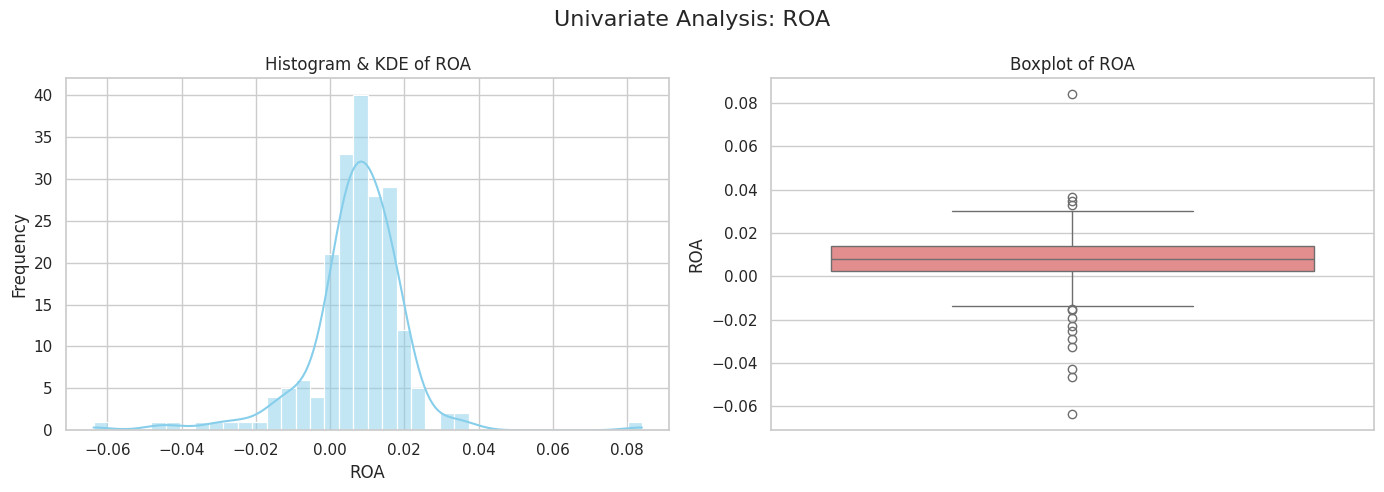

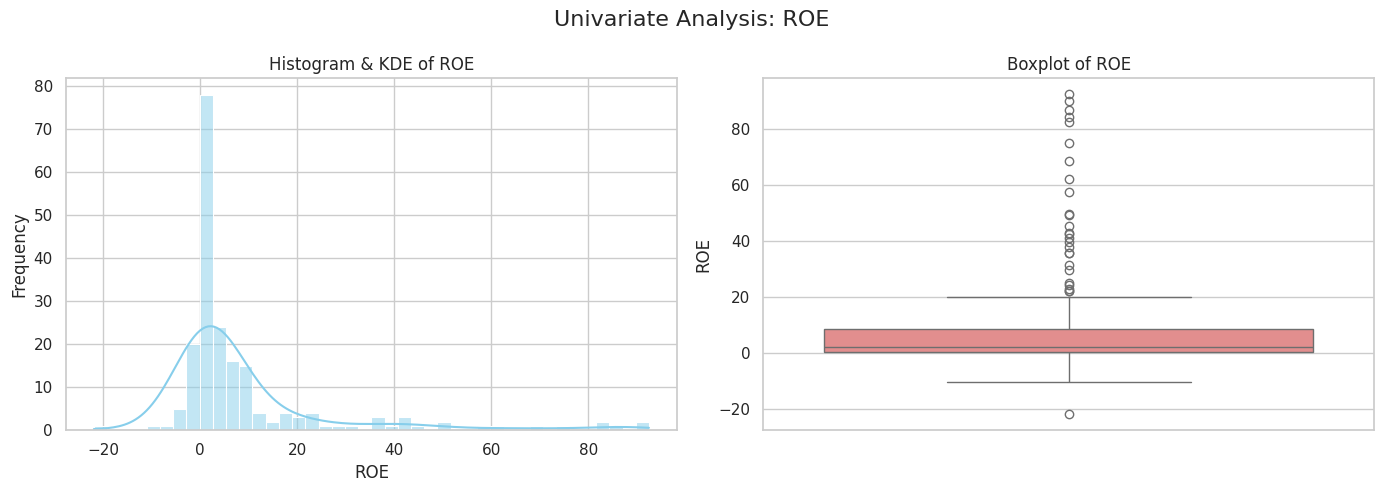

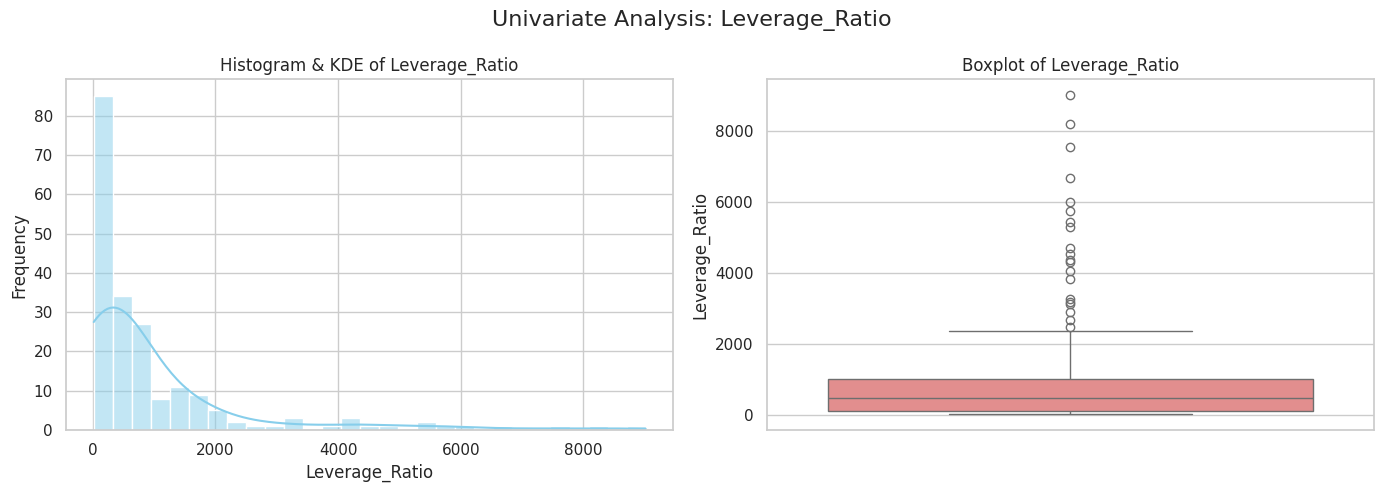

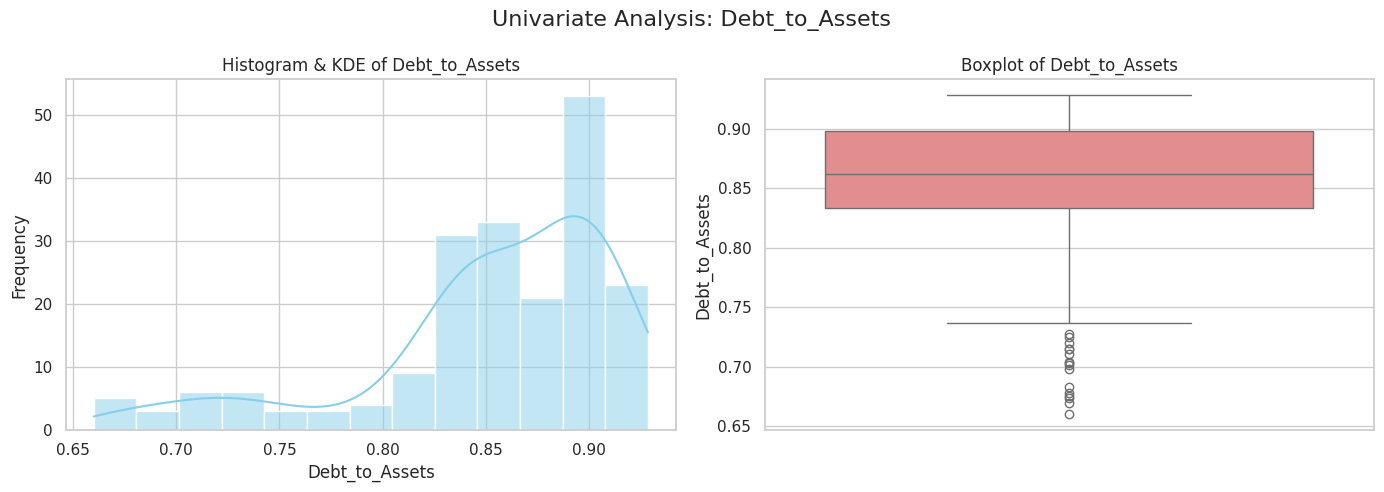

In [9]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# Configure plotting style
sns.set_theme(style="whitegrid")

ratios_to_analyze = ['ROA', 'ROE', 'Leverage_Ratio', 'Debt_to_Assets']

for col in ratios_to_analyze:
    if col in analysis_df.columns:
        fig, axes = plt.subplots(1, 2, figsize=(14, 5))

        # 1. Histogram + KDE
        sns.histplot(data=analysis_df, x=col, kde=True, ax=axes[0], color='skyblue')
        axes[0].set_title(f'Histogram & KDE of {col}')
        axes[0].set_xlabel(col)
        axes[0].set_ylabel('Frequency')

        # 2. Boxplot
        sns.boxplot(data=analysis_df, y=col, ax=axes[1], color='lightcoral')
        axes[1].set_title(f'Boxplot of {col}')
        axes[1].set_ylabel(col)

        plt.suptitle(f'Univariate Analysis: {col}', fontsize=16)
        plt.tight_layout()
        plt.show()

### Distribution Notes & Transformation Decisions

Based on the visualizations and summary statistics:

1. **Return on Assets (ROA)**
   * **Skew & Tails**: Slighly left-skewed (skew = -0.64) but relatively balanced.
   * **Outliers**: There are extreme values on both negative and positive tails, reflecting exceptional distress or performance.
   * **Decision**: Keep in raw form as ROA contains valid negative values (which makes log-transformation impossible without a shift) but consider mild Winsorization (e.g., 1st and 99th percentiles) if used in linear regressions to avoid outlier-driven biases.

2. **Return on Equity (ROE)**
   * **Skew & Tails**: Highly right-skewed (skew = 2.77) with a long positive tail.
   * **Outliers**: Clear extreme positive outliers (max = 92.51, while median is only 2.28).
   * **Decision**: Winsorization is highly recommended at the 1% and 99% limits to reduce the impact of these extreme leverage-driven return spikes.

3. **Leverage Ratio**
   * **Skew & Tails**: Extremely skewed (skew = 2.89) spanning from 15.8 to over 9000.
   * **Outliers**: Extreme right-hand outliers.
   * **Decision**: Log-transformation ($\\log_{10}$) or natural log is highly recommended since all values are strictly positive. This will compress the wide scale and pull in extreme positive values.

4. **Debt to Assets**
   * **Skew & Tails**: Left-skewed (skew = -1.38) with a concentration of observations above 80%.
   * **Outliers**: Clear lower tail outliers representing banks with exceptionally low debt leverage.
   * **Decision**: Keep in raw form since it is bounded strictly between 0 and 1 (or 0% to 100%), but apply Winsorization on the left tail if needed.

## 9. Feasibility Checks for Machine Learning Modeling (D4)

Before initiating multivariate machine learning models (such as **Isolation Forest**), we conduct formal checks to verify the viability and structure of the dataset:

### 1. Sample Size Suitability ($N = 200$)
* **Is the sample size enough for Isolation Forest?**
  * **Yes**. Isolation Forest isolates anomalous observations by randomly partitioning feature spaces. While it is highly scalable to millions of records, it functions exceptionally well on smaller datasets ($100 \le N \le 500$) without suffering from the "swamping" and "masking" effects common in larger sample sizes.
  * Standard configuration parameters (e.g., setting `max_samples` to a default of 256 or dynamically scaling it to `min(200, n_samples)`) ensure that the partitions are highly effective at detecting structural combinations of extreme values.

### 2. Feature Scaling Requirements
* **Do features need scaling?**
  * **For Isolation Forest**: Feature scaling is technically *not* strictly required because the algorithm uses orthogonal splits (decision trees), which are scale-invariant.
  * **For Model Interpretability & Downstream Algorithms**: If we use distance-based methods for validation (e.g., KNN, Mahalanobis Distance, or PCA), scaling is crucial since variables like `Leverage_Ratio_log` and `Debt_to_Assets_winsorized` span entirely different scales. Standardizing features to $\mu=0, \sigma=1$ (using `StandardScaler`) represents best practice.

### 3. Justification of Isolation Forest over IQR Baseline
* **Why is the model justified?**
  * **Multivariate Synergy**: The univariate IQR approach checks each ratio in isolation (e.g., is ROA extreme?). It completely misses "joint anomalies"—observations where no single metric is individually an outlier, but their unique combination is highly abnormal (e.g., a bank with extremely high leverage combined with unusually low debt-to-assets).
  * **Non-linear Boundaries**: Isolation Forest handles non-linear relationships and interactions seamlessly without requiring explicit parametric distribution assumptions.

### 4. Recorded Feature List for D4 Modeling
To maintain reproducibility, we will lock the following core feature variables for the upcoming modeling phase:
1. **`ROA_winsorized`**: Normalized and capped return profile.
2. **`ROE_winsorized`**: Operational return on equity.
3. **`Leverage_Ratio_log`**: Log-transformed balance-sheet scale multiplier.
4. **`Debt_to_Assets_winsorized`**: Structural capital ratio.

## 10. Insight Summary (D3 Deliverable)

This section serves as the final analytical executive summary synthesizing our exploration of the 200 bank-years dataset across the 10-year fiscal period (2017–2026).

### Core Findings & Analytical Meanings

1. **Univariate Skewness & Outlier Severity (Linked to Section 3 Plots)**
   * **Finding**: `Leverage_Ratio` and `ROE` exhibit massive right-hand tail skewness (skewness values of 2.89 and 2.77 respectively).
   * **Meaning for Review**: Raw financial metrics are highly non-normal, dominated by structural scale anomalies. Analysts must use log-transformations (applied to `Leverage_Ratio`) and winsorization (applied to `ROE` and `ROA`) to build robust, unbiased comparisons and prevent extreme points from skewing regression coefficients or baseline calculations.

2. **The 2020 Systemic Shock and Divergent Trajectories (Linked to Section 5 Trend Chart)**
   * **Finding**: The fiscal year 2020 represents a clear systemic inflection point. We observe a sharp divergence: Yes Bank experienced a historic profitability crash (ROA plunging below -4%), whereas State Bank of India (SBI) maintained stable leverage profiles.
   * **Meaning for Review**: Universal sector averages mask extreme individual distressed entities. Performance tracking systems must monitor historical variance and step-changes in individual bank trajectories rather than solely relying on static segment thresholds.

3. **Ownership Group Performance Dominance (Linked to Section 6 Segment Table)**
   * **Finding**: Small Finance Banks (SFBs) and Private Sector Banks systematically outperformed Public Sector Banks in 10-year average ROA (1.74% and 0.91% vs. 0.42% respectively).
   * **Meaning for Review**: Sector grouping is a vital predictive covariate. Anomaly detection models cannot treat all banks uniformly; a 0.5% ROA is highly normal for a Public Sector Bank but indicates severe underperformance/anomaly for an SFB.

4. **Low Multicollinearity Risks (Linked to Section 7 Correlation Heatmap & Check)**
   * **Finding**: All clean/transformed variables fell strictly below the collinearity threshold ($|r| < 0.70$). The highest relationship magnitude was between `ROE_winsorized` and `Leverage_Ratio_log` ($r = 0.62$).
   * **Meaning for Review**: The selected feature space contains highly independent operational dimensions. Predictive modeling and multivariate clustering (such as Isolation Forest) will not suffer from numerical instability or redundant variable inflation.

5. **Univariate vs. Multivariate Outlier Disconnect (Linked to Section 8 Outlier Leaderboard)**
   * **Finding**: HDFC Bank frequently dominates the top 10% statistical outlier list, driven almost entirely by its massive structural scale (very high `Leverage_Ratio_log`), despite exhibiting strong, stable profitability (ROA/ROE).
   * **Meaning for Review**: Simple univariate IQR flags over-penalize large, stable banks for scale. This highlights the critical necessity of moving towards a multivariate approach (such as Isolation Forest or Mahalanobis distance) to detect true operational anomalies rather than mere differences in balance-sheet scale.

---

### Analytical Limitations
While the current analytical pipeline is statistically sound, it has several structural limits:
* **Missing Regulatory and Asset Quality Metrics**: The dataset lacks Non-Performing Asset (NPA) ratios, Capital Adequacy Ratios (CAR/CRAR), and Liquidity Coverage Ratios (LCR). These indicators are fundamental to prudential bank supervision and systemic risk assessment.
* **Small Sample Footprint**: A panel of 200 bank-years (20 banks $\times$ 10 years) represents a relatively small sample for training data-hungry machine learning algorithms, though highly appropriate for statistical and isolation-based models.
* **Absence of Ground-Truth Anomaly Labels**: We do not possess official historical classifications of "failed," "fraudulent," or "regulatory-sanctioned" bank-years. Consequently, all anomaly validation remains unsupervised.

---

### Open Questions & Assumptions Carried into D4 Modeling
* **Scale Normalization**: We assume that logging leverage and winsorizing ROA/ROE successfully strips out pure scale effects while preserving underlying performance signals.
* **Temporal Independence**: Standard Isolation Forest ignores the temporal sequence of panel data (e.g., treating HDFC 2024 and HDFC 2025 as completely independent). In D4, we will examine if temporal sequence lag features should be engineered to capture anomalous consecutive shocks.

## 4. Transforming the Ratios

Based on our univariate analysis, we will create transformed variables to limit outlier distortion:
- **`Leverage_Ratio_log`**: Natural log of `Leverage_Ratio` (strictly positive, highly right-skewed).
- **Winsorized Variables** (at 1% and 99%): `ROA_winsorized`, `ROE_winsorized`, and `Debt_to_Assets_winsorized` to limit heavy tail outliers while preserving original scales.

In [10]:
from scipy.stats import mstats

# 1. Log transformation for Leverage Ratio
analysis_df['Leverage_Ratio_log'] = np.log(analysis_df['Leverage_Ratio'])

# 2. Winsorization (1% on each tail)
analysis_df['ROA_winsorized'] = mstats.winsorize(analysis_df['ROA'], limits=[0.01, 0.01])
analysis_df['ROE_winsorized'] = mstats.winsorize(analysis_df['ROE'], limits=[0.01, 0.01])
analysis_df['Debt_to_Assets_winsorized'] = mstats.winsorize(analysis_df['Debt_to_Assets'], limits=[0.01, 0.01])

# Display new statistics comparing raw vs transformed variables
transformed_cols = ['Leverage_Ratio', 'Leverage_Ratio_log', 'ROE', 'ROE_winsorized', 'ROA', 'ROA_winsorized']
display(analysis_df[transformed_cols].agg(['mean', 'median', 'std', 'skew']).T)

,mean,median,std,skew
Metric,,,,
Leverage_Ratio,975.162685,477.178971,1518.801768,2.888501
Leverage_Ratio_log,5.843012,6.167811,1.592979,-0.156038
ROE,9.172664,2.283787,18.197502,2.787536
ROE_winsorized,9.172664,2.283787,18.197502,2.787536
ROA,0.006961,0.008174,0.012080,-1.398450
ROA_winsorized,0.006961,0.008174,0.012080,-1.398450


## 5. Time Trends & Event Annotation

In this section, we analyze how the ratios evolve over the 10-year period (2017 to 2026). Specifically, we will:
1. Compute the sector median and spread (25th to 75th percentile) for each ratio.
2. Plot line charts for individual banks of interest (e.g., **Yes Bank**, **SBI** to represent public sector mergers, and a stable peer) against the sector median.
3. Overlay annotations for key systemic events:
   - **Yes Bank Crisis (FY2020)**: Marked by massive capital depletion and reconstruction.
   - **COVID-19 Pandemic (2020–2021)**: Impacting credit costs and asset quality.
   - **Public-Sector Bank Mergers (2020)**: Consolidating multiple public sector banks.

In [11]:
# Calculate annual sector median and spread (IQR)
annual_stats = analysis_df.groupby('Year')[['ROA_winsorized', 'ROE_winsorized', 'Leverage_Ratio_log', 'Debt_to_Assets_winsorized']].agg(['median', lambda x: np.percentile(x, 25), lambda x: np.percentile(x, 75)])

# Rename columns for clarity
clean_cols = []
for col in ['ROA_winsorized', 'ROE_winsorized', 'Leverage_Ratio_log', 'Debt_to_Assets_winsorized']:
    clean_cols.extend([f"{col}_median", f"{col}_p25", f"{col}_p75"])
annual_stats.columns = clean_cols
annual_stats = annual_stats.reset_index()

# Let's inspect the calculated sector metrics
display(annual_stats.head())

,Year,ROA_winsorized_median,ROA_winsorized_p25,ROA_winsorized_p75,ROE_winsorized_median,ROE_winsorized_p25,ROE_winsorized_p75,Leverage_Ratio_log_median,Leverage_Ratio_log_p25,Leverage_Ratio_log_p75,Debt_to_Assets_winsorized_median,Debt_to_Assets_winsorized_p25,Debt_to_Assets_winsorized_p75
0,2017,0.006557,0.000960,0.015661,2.651842,0.301907,4.938153,6.137645,5.107121,6.967366,0.877769,0.824915,0.905691
1,2018,0.002914,-0.007754,0.014038,0.570217,-3.453590,3.545963,5.976184,4.597861,6.885941,0.884084,0.849520,0.903916
2,2019,0.001349,-0.009358,0.009075,1.470820,-0.721059,3.409543,6.079670,4.558893,6.855276,0.878403,0.846450,0.901168
3,2020,0.002178,-0.004856,0.010091,1.208694,-0.674559,4.580842,6.112463,4.484574,6.676497,0.863641,0.848152,0.900774
4,2021,0.004829,0.002741,0.009010,1.624957,0.370397,5.647073,6.165826,4.201352,6.689738,0.852981,0.828151,0.899757


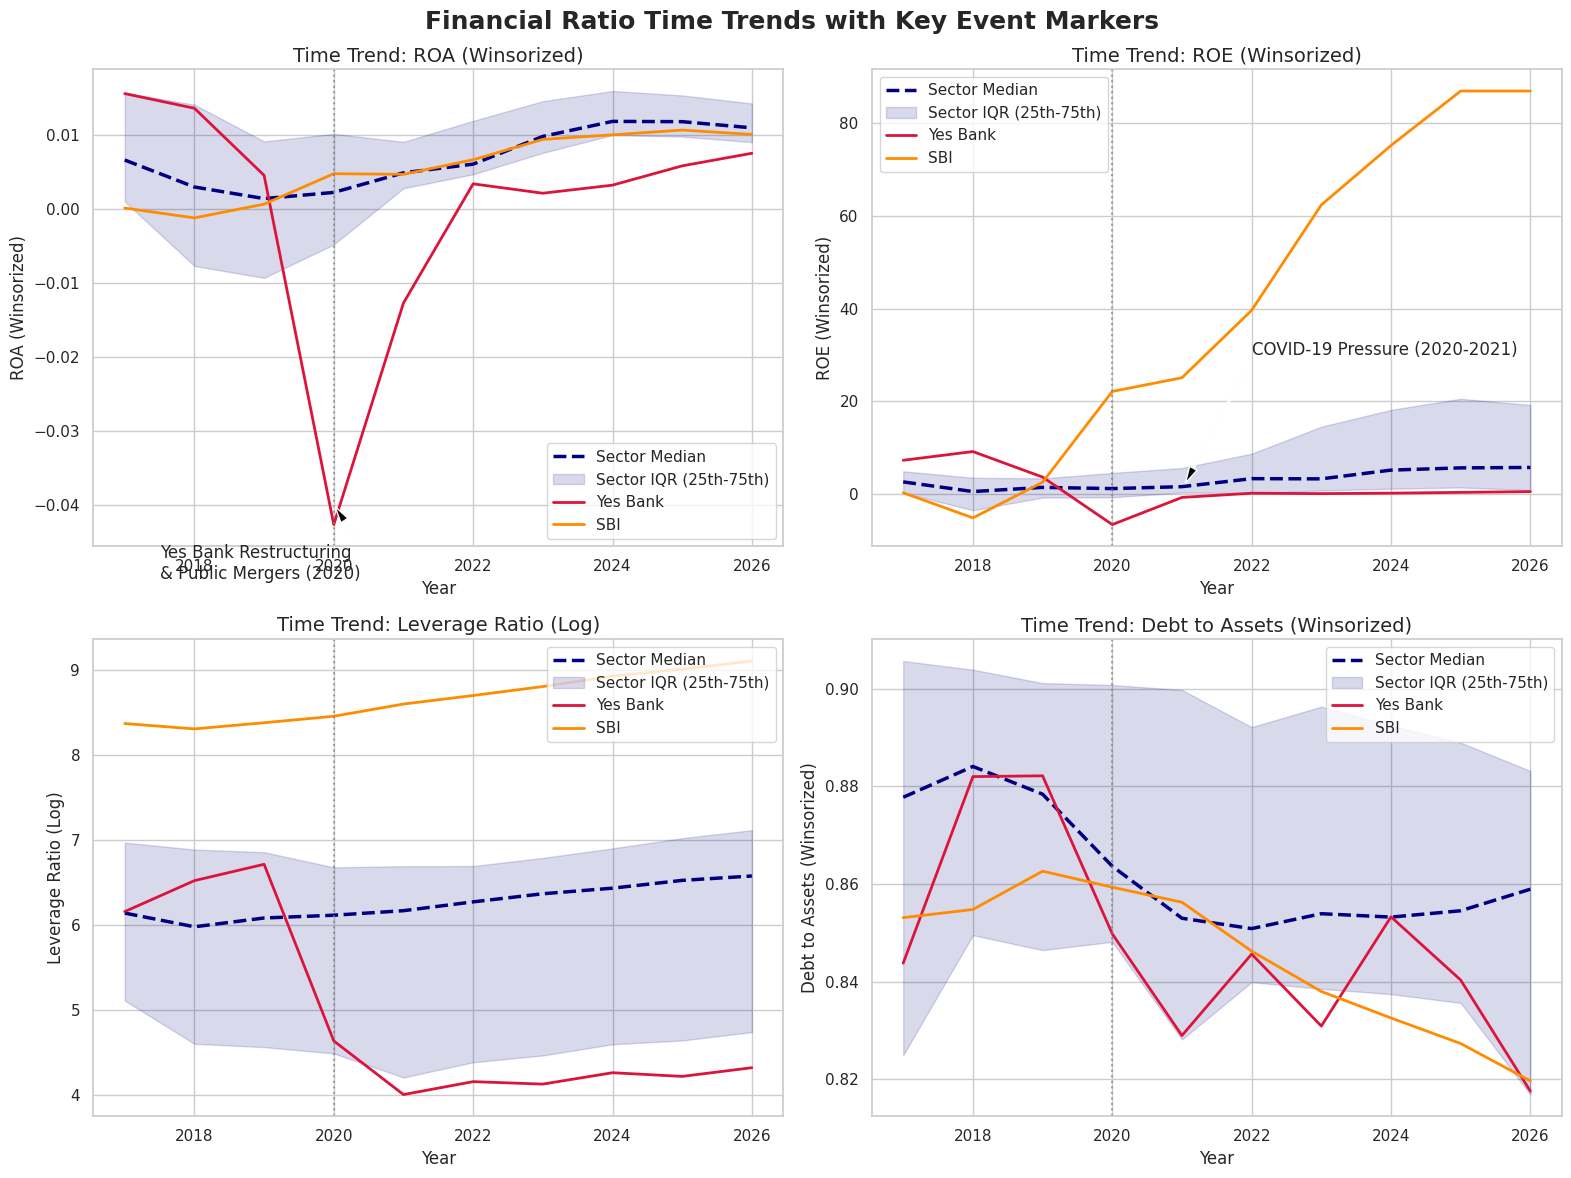

In [12]:
import matplotlib.pyplot as plt

# Set plotting environment
fig, axes = plt.subplots(2, 2, figsize=(16, 12))
axes = axes.flatten()

ratios = [
    ('ROA_winsorized', 'ROA (Winsorized)'),
    ('ROE_winsorized', 'ROE (Winsorized)'),
    ('Leverage_Ratio_log', 'Leverage Ratio (Log)'),
    ('Debt_to_Assets_winsorized', 'Debt to Assets (Winsorized)')
]

# We will track Yes Bank and SBI (State Bank of India) to see how they contrast with the peer median
focus_banks = ['Yes Bank', 'SBI']
colors = {'Yes Bank': 'crimson', 'SBI': 'darkorange'}

for i, (col, label) in enumerate(ratios):
    ax = axes[i]

    # Plot sector median and IQR spread
    ax.plot(annual_stats['Year'], annual_stats[f'{col}_median'], label='Sector Median', color='navy', linewidth=2.5, linestyle='--')
    ax.fill_between(annual_stats['Year'], annual_stats[f'{col}_p25'], annual_stats[f'{col}_p75'], color='navy', alpha=0.15, label='Sector IQR (25th-75th)')

    # Plot specific banks for comparison
    for bank in focus_banks:
        bank_data = analysis_df[analysis_df['Bank'] == bank]
        ax.plot(bank_data['Year'], bank_data[col], label=f'{bank}', color=colors[bank], linewidth=2)

    # Highlight/Annotate specific historical points
    ax.axvline(x=2020, color='gray', linestyle=':', alpha=0.7)

    # Subplot specific annotations
    if col == 'ROA_winsorized':
        ax.annotate('Yes Bank Restructuring\n& Public Mergers (2020)', xy=(2020, -0.04), xytext=(2017.5, -0.05),
                    arrowprops=dict(facecolor='black', shrink=0.05, width=1, headwidth=6))
    if col == 'ROE_winsorized':
        ax.annotate('COVID-19 Pressure (2020-2021)', xy=(2021, 1), xytext=(2022, 30),
                    arrowprops=dict(facecolor='black', shrink=0.05, width=1, headwidth=6))

    ax.set_title(f'Time Trend: {label}', fontsize=14)
    ax.set_xlabel('Year')
    ax.set_ylabel(label)
    ax.legend(loc='best')

plt.suptitle('Financial Ratio Time Trends with Key Event Markers', fontsize=18, weight='bold')
plt.tight_layout()
plt.show()

## 6. Peer and Bank Comparison

In this section, we conduct a structural cross-sectional analysis across our 20 banks.

We will:
1. Classify banks into three primary peer groups: **Public Sector**, **Private Sector**, and **Small Finance Banks (SFBs)**.
2. Calculate overall historical means for each bank and rank them across our core metrics.
3. Compare performance segments dynamically.
4. Visualise peer-median deviations for key metrics like Return on Assets (ROA).

In [13]:
# 1. Define Ownership / Structural Segments for the 20 Banks
bank_groups = {
    'AU Small Finance': 'Small Finance Bank',
    'Axis Bank': 'Private',
    'Bandhan Bank': 'Private',
    'Bank of Baroda': 'Public',
    'Bank of India': 'Public',
    'Bank of Maharashtra': 'Public',
    'Canara Bank': 'Public',
    'Central Bank': 'Public',
    'City Union': 'Private',
    'Federal Bank': 'Private',
    'HDFC Bank': 'Private',
    'ICICI Bank': 'Private',
    'IDBI Bank': 'Private', # Categorized generally as Private/Other by RBI in recent years
    'Indian Bank': 'Public',
    'Indian Overseas': 'Public',
    'Karur Vysya': 'Private',
    'PNB': 'Public',
    'SBI': 'Public',
    'Union Bank (I)': 'Public',
    'Yes Bank': 'Private'
}

analysis_df['Bank_Group'] = analysis_df['Bank'].map(bank_groups)

# Let's verify that all banks are grouped successfully
print("Bank counts by segment:")
display(analysis_df.groupby('Bank_Group')['Bank'].nunique().to_frame(name='Number of Banks'))

Bank counts by segment:


,Number of Banks
Bank_Group,
Private,7
Public,6
Small Finance Bank,1


In [14]:
# 2. Calculate average metrics over the entire 10-year period for each bank and rank them
bank_ranks = analysis_df.groupby(['Bank_Group', 'Bank'])[[
    'ROA_winsorized',
    'ROE_winsorized',
    'Leverage_Ratio_log',
    'Debt_to_Assets_winsorized'
]].mean().reset_index()

# Rank banks by overall ROA
bank_ranks['ROA_Rank'] = bank_ranks['ROA_winsorized'].rank(ascending=False, method='min').astype(int)

print("--- Overall Bank Rankings by 10-Year Average ROA (Highest to Lowest) ---")
display(bank_ranks.sort_values(by='ROA_Rank'))

--- Overall Bank Rankings by 10-Year Average ROA (Highest to Lowest) ---


Metric,Bank_Group,Bank,ROA_winsorized,ROE_winsorized,Leverage_Ratio_log,Debt_to_Assets_winsorized,ROA_Rank
1,Private,Bandhan Bank,0.019930,1.231439,4.248826,0.821849,1
13,Small Finance Bank,AU Small Finance,0.017381,2.556973,4.877871,0.837624,2
3,Private,HDFC Bank,0.016971,58.560691,8.092211,0.817665,3
4,Private,ICICI Bank,0.012760,18.632734,7.134539,0.712963,4
2,Private,Federal Bank,0.009424,5.374737,6.257637,0.888055,5
0,Private,Axis Bank,0.009021,20.501877,7.555730,0.854831,6
10,Public,Indian Bank,0.007018,4.184920,6.341250,0.897778,7
11,Public,SBI,0.005526,39.600208,8.666526,0.844983,8
7,Public,Bank of Baroda,0.005094,8.420960,7.311692,0.887820,9
9,Public,Canara Bank,0.003920,3.503379,6.739519,0.898370,10


In [15]:
# 3. Group comparison: Public vs. Private vs. Small Finance Banks
segment_summary = analysis_df.groupby('Bank_Group')[[
    'ROA_winsorized',
    'ROE_winsorized',
    'Leverage_Ratio_log',
    'Debt_to_Assets_winsorized'
]].agg(['mean', 'median'])

print("--- Structural Segment Performance Profiles ---")
display(segment_summary)

--- Structural Segment Performance Profiles ---


Metric             ROA_winsorized           ROE_winsorized            \
                             mean    median           mean    median   
Bank_Group                                                             
Private                  0.009104  0.011614      15.029469  4.066961   
Public                   0.004238  0.004788       9.343160  2.268748   
Small Finance Bank       0.017381  0.015667       2.556973  2.561019   

Metric             Leverage_Ratio_log           Debt_to_Assets_winsorized  \
                                 mean    median                      mean   
Bank_Group                                                                  
Private                      6.000048  6.465855                  0.825408   
Public                       6.674402  6.558191                  0.888733   
Small Finance Bank           4.877871  5.014190                  0.837624   

Metric                        
                      median  
Bank_Group                    
Private             0.842028  
Public              0.893113  
Small Finance Bank  0.847381

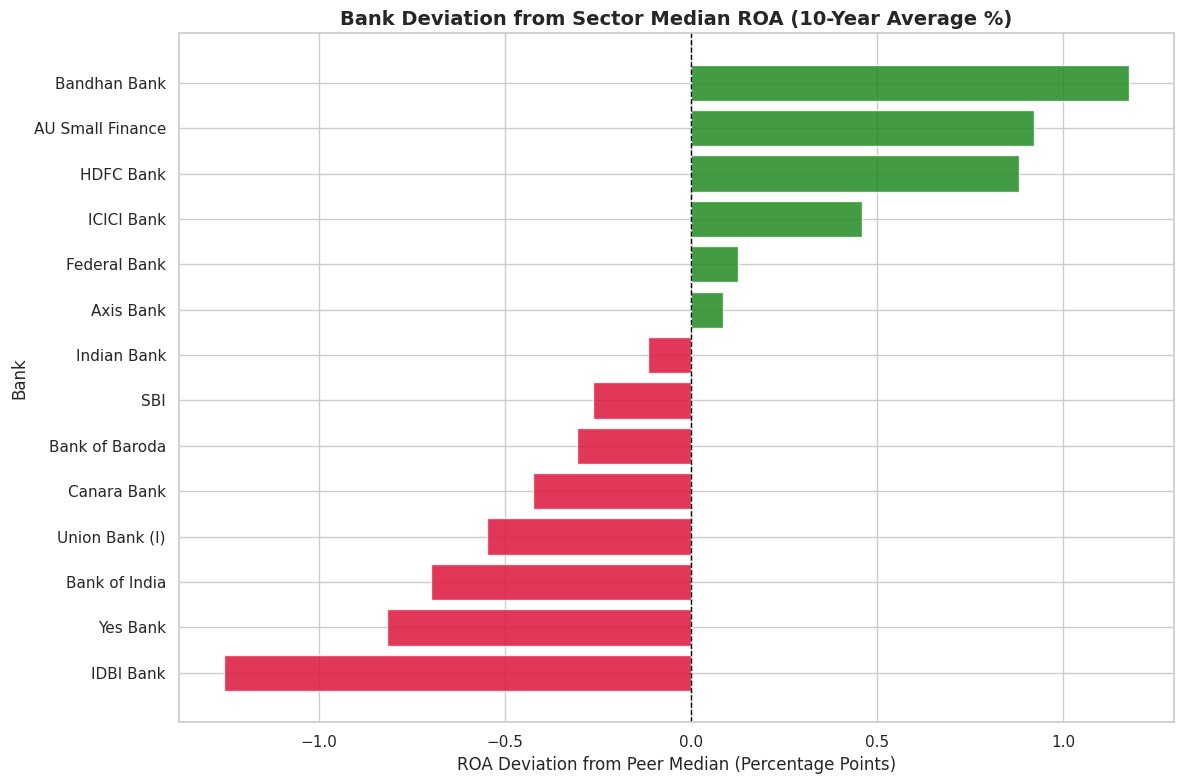

In [16]:
# 4. Plot Peer-Median Difference Charts
# Calculate overall median for reference
overall_roa_median = analysis_df['ROA_winsorized'].median()

# Calculate each bank's average deviation from the sector median
bank_ranks['ROA_Deviation'] = bank_ranks['ROA_winsorized'] - overall_roa_median
bank_ranks_sorted = bank_ranks.sort_values(by='ROA_Deviation')

plt.figure(figsize=(12, 8))
colors = ['crimson' if x < 0 else 'forestgreen' for x in bank_ranks_sorted['ROA_Deviation']]

plt.barh(bank_ranks_sorted['Bank'], bank_ranks_sorted['ROA_Deviation'] * 100, color=colors, alpha=0.85)
plt.axvline(x=0, color='black', linestyle='--', linewidth=1)

plt.title('Bank Deviation from Sector Median ROA (10-Year Average %)', fontsize=14, weight='bold')
plt.xlabel('ROA Deviation from Peer Median (Percentage Points)')
plt.ylabel('Bank')
plt.tight_layout()
plt.show()

## 7. Relationship and Correlation Analysis

In this section, we study how our key financial indicators relate to one another:
1. We will compute Pearson correlation coefficients across both the raw and transformed variables and visualize them with a heatmap.
2. We will programmatically flag any highly correlated pairs ($|r| > 0.70$) to prevent multicollinearity in modeling steps.
3. We will build diagnostic scatter plots for key relationship pairs, highlighting and labeling prominent bank-year outliers.

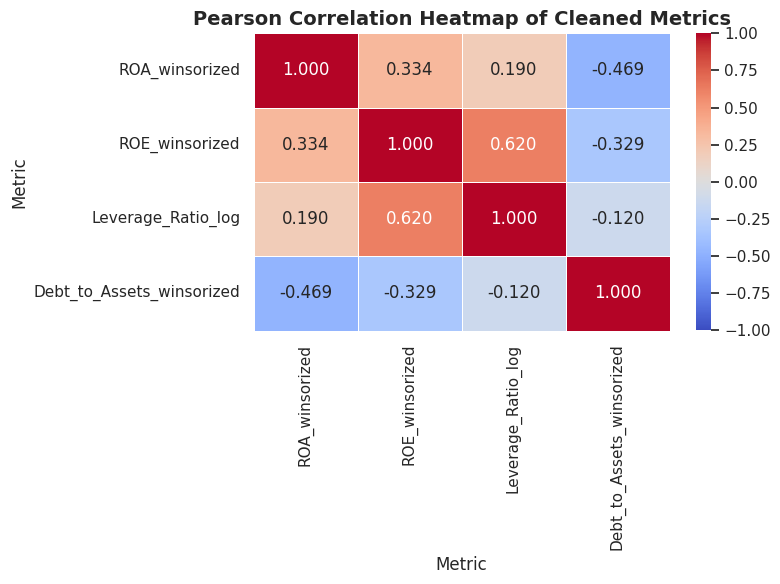

In [17]:
import seaborn as sns
import matplotlib.pyplot as plt

# Define variables of interest for correlation
corr_cols = [
    'ROA_winsorized', 'ROE_winsorized',
    'Leverage_Ratio_log', 'Debt_to_Assets_winsorized'
]

# Compute correlation matrix
corr_matrix = analysis_df[corr_cols].corr()

# Plot the correlation heatmap
plt.figure(figsize=(8, 6))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt=".3f", vmin=-1, vmax=1, linewidths=0.5)
plt.title('Pearson Correlation Heatmap of Cleaned Metrics', fontsize=14, weight='bold')
plt.tight_layout()
plt.show()

In [18]:
# Programmatically find and flag highly correlated pairs (|r| > 0.7)
threshold = 0.70
high_corr_pairs = []

for i in range(len(corr_cols)):
    for j in range(i + 1, len(corr_cols)):
        val = corr_matrix.iloc[i, j]
        if abs(val) >= threshold:
            high_corr_pairs.append((corr_cols[i], corr_cols[j], val))

print("--- Programmatic Multicollinearity / High Correlation Check ---")
if high_corr_pairs:
    print(f"Flagged pairs with correlation magnitude above {threshold}:")
    for p1, p2, val in high_corr_pairs:
        print(f"  * {p1} <-> {p2} : {val:.4f}")
else:
    print(f"Success: No pairs exceeded the |r| > {threshold} threshold. Multicollinearity risks are low.")

--- Programmatic Multicollinearity / High Correlation Check ---
Success: No pairs exceeded the |r| > 0.7 threshold. Multicollinearity risks are low.


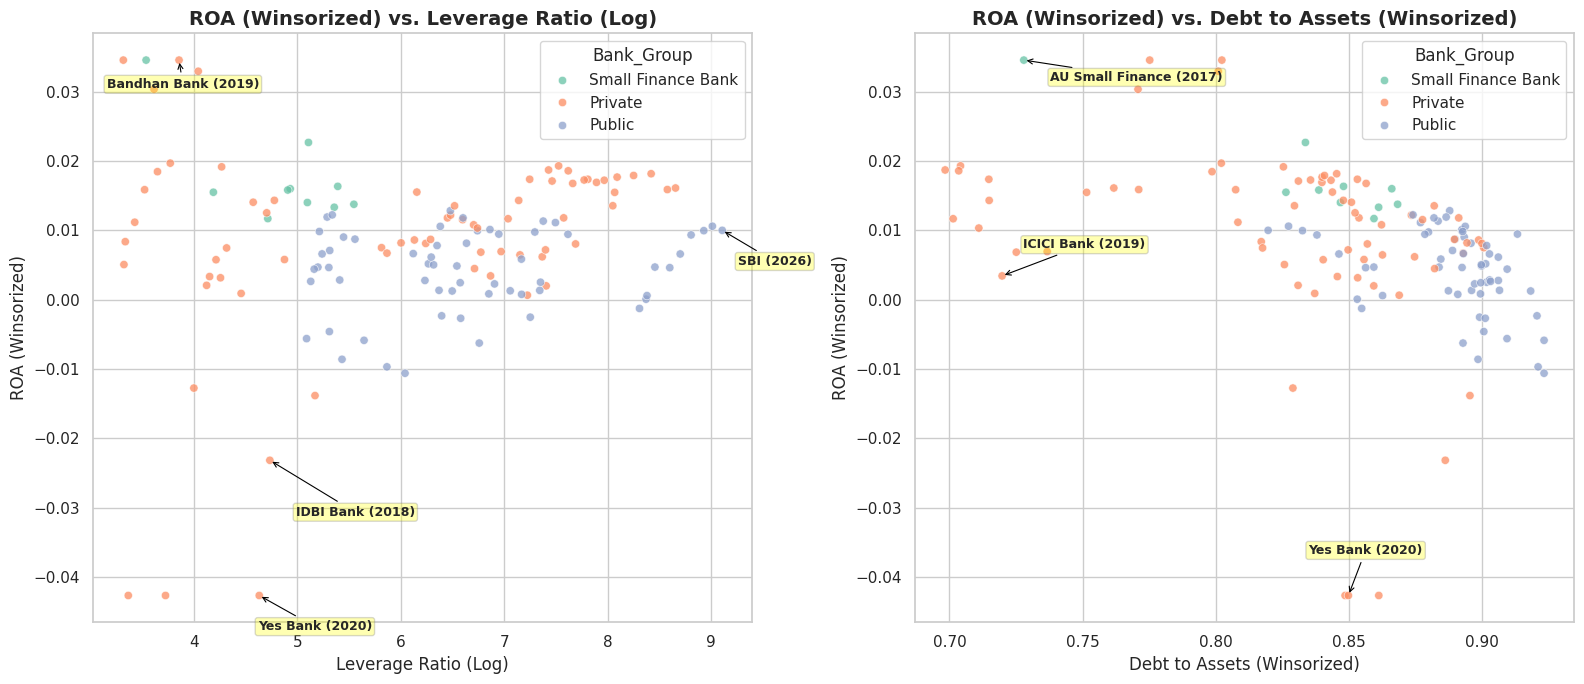

In [20]:
import matplotlib.pyplot as plt
import seaborn as sns

fig, axes = plt.subplots(1, 2, figsize=(16, 7))

# Scatter 1: ROA vs. Leverage Ratio (Log)
sns.scatterplot(data=analysis_df, x='Leverage_Ratio_log', y='ROA_winsorized', hue='Bank_Group', palette='Set2', alpha=0.75, ax=axes[0])
axes[0].set_title('ROA (Winsorized) vs. Leverage Ratio (Log)', fontsize=14, weight='bold')
axes[0].set_xlabel('Leverage Ratio (Log)', fontsize=12)
axes[0].set_ylabel('ROA (Winsorized)', fontsize=12)

# Define key historical anomalies to label clearly without overlapping text
outliers_1_labels = [
    ('Yes Bank', 2020, -0.015, -0.005),
    ('IDBI Bank', 2018, 0.25, -0.008),
    ('Bandhan Bank', 2019, -0.7, -0.004),
    ('SBI', 2026, 0.15, -0.005)
]

for bank, year, x_off, y_off in outliers_1_labels:
    row = analysis_df[(analysis_df['Bank'] == bank) & (analysis_df['Year'] == year)]
    if not row.empty:
        row_data = row.iloc[0]
        axes[0].annotate(f"{bank} ({year})",
                        xy=(row_data['Leverage_Ratio_log'], row_data['ROA_winsorized']),
                        xytext=(row_data['Leverage_Ratio_log'] + x_off, row_data['ROA_winsorized'] + y_off),
                        arrowprops=dict(arrowstyle="->", color='black', lw=0.8),
                        fontsize=9, weight='semibold',
                        bbox=dict(boxstyle="round,pad=0.2", fc="yellow", alpha=0.3, ec="gray"))

# Scatter 2: ROA vs. Debt to Assets (Winsorized)
sns.scatterplot(data=analysis_df, x='Debt_to_Assets_winsorized', y='ROA_winsorized', hue='Bank_Group', palette='Set2', alpha=0.75, ax=axes[1])
axes[1].set_title('ROA (Winsorized) vs. Debt to Assets (Winsorized)', fontsize=14, weight='bold')
axes[1].set_xlabel('Debt to Assets (Winsorized)', fontsize=12)
axes[1].set_ylabel('ROA (Winsorized)', fontsize=12)

# Identify distinct coordinates to annotate clearly
outliers_2_labels = [
    ('AU Small Finance', 2017, 0.01, -0.003),
    ('ICICI Bank', 2019, 0.008, 0.004),
    ('Yes Bank', 2020, -0.015, 0.006)
]

for bank, year, x_off, y_off in outliers_2_labels:
    row = analysis_df[(analysis_df['Bank'] == bank) & (analysis_df['Year'] == year)]
    if not row.empty:
        row_data = row.iloc[0]
        axes[1].annotate(f"{bank} ({year})",
                        xy=(row_data['Debt_to_Assets_winsorized'], row_data['ROA_winsorized']),
                        xytext=(row_data['Debt_to_Assets_winsorized'] + x_off, row_data['ROA_winsorized'] + y_off),
                        arrowprops=dict(arrowstyle="->", color='black', lw=0.8),
                        fontsize=9, weight='semibold',
                        bbox=dict(boxstyle="round,pad=0.2", fc="yellow", alpha=0.3, ec="gray"))

plt.tight_layout()
plt.show()

## 8. Outlier and Anomaly Preview (Statistical Baseline)

In this section, we build a baseline statistical anomaly detection system for the 200 bank-years:
1. **IQR-Based Flagging**: We will flag any observation where a ratio falls outside the standard interval: $[Q_1 - 1.5 \times IQR, \quad Q_3 + 1.5 \times IQR]$.
2. **Anomaly Score**: We will count the total number of ratio dimensions flagged for each bank-year to serve as an aggregate anomaly score.
3. **Top 10% Anomalies**: We will extract the 20 most unusual bank-years (top 10% out of 200) and review their specific metrics to identify recurring banks.

In [21]:
import numpy as np
import pandas as pd

# Create a copy of the dataset for anomaly profiling
anomaly_df = analysis_df.copy()

# Define the ratios we want to check
target_ratios = ['ROA_winsorized', 'ROE_winsorized', 'Leverage_Ratio_log', 'Debt_to_Assets_winsorized']

# Initialize anomaly flags
for col in target_ratios:
    q1 = anomaly_df[col].quantile(0.25)
    q3 = anomaly_df[col].quantile(0.75)
    iqr = q3 - q1

    lower_bound = q1 - 1.5 * iqr
    upper_bound = q3 + 1.5 * iqr

    # Flag as 1 if outside the bounds, else 0
    anomaly_df[f'{col}_flag'] = ((anomaly_df[col] < lower_bound) | (anomaly_df[col] > upper_bound)).astype(int)

# Calculate overall anomaly score as the sum of flags across the 4 ratios
flag_cols = [f'{col}_flag' for col in target_ratios]
anomaly_df['Anomaly_Score'] = anomaly_df[flag_cols].sum(axis=1)

# Display summary counts of flagged dimensions
print("Distribution of anomaly flags per bank-year:")
display(anomaly_df['Anomaly_Score'].value_counts().to_frame(name='Number of Bank-Years'))

Distribution of anomaly flags per bank-year:


/usr/local/lib/python3.13/dist-packages/numpy/lib/_function_base_impl.py:4809: UserWarning: Warning: 'partition' will ignore the 'mask' of the MaskedArray.
  arr.partition(
/usr/local/lib/python3.13/dist-packages/numpy/lib/_function_base_impl.py:4809: UserWarning: Warning: 'partition' will ignore the 'mask' of the MaskedArray.
  arr.partition(
/usr/local/lib/python3.13/dist-packages/numpy/lib/_function_base_impl.py:4809: UserWarning: Warning: 'partition' will ignore the 'mask' of the MaskedArray.
  arr.partition(
/usr/local/lib/python3.13/dist-packages/numpy/lib/_function_base_impl.py:4809: UserWarning: Warning: 'partition' will ignore the 'mask' of the MaskedArray.
  arr.partition(
/usr/local/lib/python3.13/dist-packages/numpy/lib/_function_base_impl.py:4809: UserWarning: Warning: 'partition' will ignore the 'mask' of the MaskedArray.
  arr.partition(
/usr/local/lib/python3.13/dist-packages/numpy/lib/_function_base_impl.py:4809: UserWarning: Warning: 'partition' will ignore the 'mask'

,Number of Bank-Years
Anomaly_Score,
0,150
1,44
2,6


In [22]:
# Identify the top 10% most unusual bank-years (20 observations out of 200)
# To resolve ties and get exactly 20, we sort by absolute deviation metrics
# We'll calculate a simple average of absolute Z-scores for sorting
for col in target_ratios:
    mean = anomaly_df[col].mean()
    std = anomaly_df[col].astype(float).std()
    anomaly_df[f'{col}_z'] = (anomaly_df[col] - mean) / std

anomaly_df['Avg_Abs_Z'] = anomaly_df[[f'{col}_z' for col in target_ratios]].abs().mean(axis=1)

# Get top 20 anomalies sorted by average z-score magnitude
top_anomalies = anomaly_df.sort_values(by='Avg_Abs_Z', ascending=False).head(20)

print("--- Top 10% Most Anomalous Bank-Years (Ordered by Average Z-Score Deviation) ---")
display(top_anomalies[['Bank', 'Year', 'Bank_Group', 'ROA_winsorized', 'ROE_winsorized', 'Leverage_Ratio_log', 'Debt_to_Assets_winsorized', 'Anomaly_Score', 'Avg_Abs_Z']])

--- Top 10% Most Anomalous Bank-Years (Ordered by Average Z-Score Deviation) ---


Metric,Bank,Year,Bank_Group,ROA_winsorized,ROE_winsorized,Leverage_Ratio_log,Debt_to_Assets_winsorized,Anomaly_Score,Avg_Abs_Z
88,HDFC Bank,2025,Private,0.016118,86.907357,8.655157,0.761708,1,2.069907
87,HDFC Bank,2024,Private,0.015896,84.326554,8.576415,0.771055,1,1.979163
179,SBI,2026,Public,0.010010,86.907357,9.106620,0.819644,1,1.776818
178,SBI,2025,Public,0.010605,86.907357,9.011282,0.827315,1,1.742707
86,HDFC Bank,2023,Private,0.018178,82.436529,8.419596,0.845394,1,1.671026
113,IDBI Bank,2020,Private,-0.042685,-1.236465,3.366172,0.861202,1,1.595981
93,I O B,2020,NaN,-0.032706,-0.518793,2.763939,0.875904,1,1.534399
177,SBI,2024,Public,0.009962,75.168265,8.928662,0.832544,1,1.533731
0,AU Small Finance,2017,Small Finance Bank,0.034575,2.891750,3.538366,0.727914,2,1.529170
112,IDBI Bank,2019,Private,-0.042685,-1.937202,3.725866,0.848546,1,1.527459


In [23]:
# Analyze recurrence: Check which banks appear most frequently in our anomaly leaderboard
recurrence_report = top_anomalies['Bank'].value_counts().to_frame(name='Appearance Count in Top 10% Anomalies')
recurrence_report['Segment'] = recurrence_report.index.map(bank_groups)

print("--- Recurring Anomalous Banks (Presence in Top 10% Anomalies) ---")
display(recurrence_report)

--- Recurring Anomalous Banks (Presence in Top 10% Anomalies) ---


,Appearance Count in Top 10% Anomalies,Segment
Bank,,
HDFC Bank,5,Private
SBI,3,Public
ICICI Bank,3,Private
I O B,2,NaN
IDBI Bank,2,Private
Kotak Mah. Bank,2,NaN
AU Small Finance,1,Small Finance Bank
Yes Bank,1,Private
Bank of Maha,1,NaN
